# Практичні роботи 4–7
## Мініпроєкт «Порівняння класичних моделей класифікації»

**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студент:** Трапезніков Максим  
**Група:** ІН-42  
**Дата виконання:** 26.11.2026

### Постановка задачі
- **Об'єкт дослідження:** один пацієнт із набору даних *Heart Disease Dataset* (UCI Cleveland).
- **Вхідні ознаки:** 13 клінічних і діагностичних характеристик (`age`, `sex`, `cp`, `trestbps`, `chol`, `fbs`, `restecg`, `thalach`, `exang`, `oldpeak`, `slope`, `ca`, `thal`).
- **Цільова змінна:** `target` (`0` — ознаки серцевого захворювання відсутні; `1` — ознаки серцевого захворювання наявні, об'єднані початкові значення `1–4`).
- **Тип задачі та кількість класів:** бінарна класифікація (`2` класи).
- **Позитивний клас:** `1` (наявність ознак серцевого захворювання).
- **Практична мета:** за характеристиками пацієнта визначити наявність ознак серцевого захворювання. *Етичне застереження: результати мають навчальний характер і не є медичним діагнозом.*
- **Основна метрика експерименту (визначена до старту):** **`CV F1`** (для балансу між precision і recall позитивного класу), додаткові орієнтири — **`CV ROC AUC`** та **`CV Recall`**.

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Імпорт бібліотек та налаштування шляхів проєкту

In [16]:
from pathlib import Path
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay
)
from IPython.display import display

warnings.filterwarnings("ignore")

PROJECT_DIR = Path("classification-mini-project")
DATA_DIR = PROJECT_DIR / "data"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

for folder in (DATA_DIR, MODELS_DIR, REPORTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "heart_disease.csv"
MODEL_PATH = MODELS_DIR / "best_classifier.joblib"
CV_REPORT_PATH = REPORTS_DIR / "cv_model_comparison.csv"
TEST_REPORT_PATH = REPORTS_DIR / "final_test_metrics.csv"

print("Робочі директорії підготовлено:", PROJECT_DIR.resolve())

Робочі директорії підготовлено: /content/classification-mini-project


---
# Частина І. Практична робота 4
## Підготовка даних, Pipeline і логістична регресія

### 1. Завантаження та первинний аудит даних

In [17]:
# Якщо локального heart_disease.csv ще немає, завантажуємо офіційний Cleveland dataset з UCI
if not DATA_PATH.exists():
    local_candidate = Path("heart_disease.csv")
    if local_candidate.exists():
        pd.read_csv(local_candidate).to_csv(DATA_PATH, index=False)
    else:
        uci_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
        cols = [
            "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
        ]
        raw_df = pd.read_csv(uci_url, names=cols, na_values="?")
        raw_df["target"] = (raw_df["target"] > 0).astype(int)
        raw_df.to_csv(DATA_PATH, index=False)

data = pd.read_csv(DATA_PATH)
display(data.head())

print("Розмір таблиці:", data.shape)
print("\nТипи даних:")
print(data.dtypes)
print("\nПропущені значення за стовпцями:")
print(data.isna().sum())
print("Загальна кількість пропусків:", int(data.isna().sum().sum()))
print("\nРозподіл цільової змінної target:")
print(data["target"].value_counts().sort_index())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Розмір таблиці: (303, 14)

Типи даних:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Пропущені значення за стовпцями:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
Загальна кількість пропусків: 6

Розподіл цільової змінної target:
target
0    164
1    139
Name: count, dtype: int64


### Таблиця первинного аудиту набору даних

| Характеристика | Значення |
| :--- | :--- |
| Кількість об'єктів | `303` |
| Кількість вхідних ознак | `13` |
| Числові ознаки (`5`) | `age`, `trestbps`, `chol`, `thalach`, `oldpeak` |
| Категоріальні ознаки (`8`) | `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal` |
| Кількість пропусків | `6` (`4` у `ca`, `2` у `thal`) |
| Кількість класів | `2` (`0` — `164` об'єкти, `1` — `139` об'єктів) |
| Позитивний клас | `1` |

### 2. Стратифіковане розбиття на `train`/`test` та схема крос-валідації
Тестова вибірка (`20%`) відокремлюється один раз і **закривається до Практичної роботи 7**.

In [18]:
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

X = data.drop(columns=["target"])
y = data["target"]

assert set(y.unique()) == {0, 1}, "Цільова змінна має містити лише класи 0 та 1."

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
print("Частка класу 1 у train:", round(float(y_train.mean()), 4))
print("Частка класу 1 у test: ", round(float(y_test.mean()), 4))

X_train: (242, 13), y_train: (242,)
X_test:  (61, 13), y_test:  (61,)
Частка класу 1 у train: 0.4587
Частка класу 1 у test:  0.459


### 3. Конвеєр попередньої обробки (`ColumnTransformer`) та вплив масштабування на `LogisticRegression`

In [19]:
def build_preprocessor(scale_numeric=True):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    else:
        num_steps.append(("scaler", "passthrough"))

    cat_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), numeric_columns),
        ("cat", Pipeline(cat_steps), categorical_columns)
    ])


scoring_metrics = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy"
}

lr_scaling_results = []
for label, use_scale in [("Без масштабування (passthrough)", False), ("Зі StandardScaler", True)]:
    pipe = Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=use_scale)),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42))
    ])
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics)
    pipe.fit(X_train, y_train)
    n_iter = int(pipe.named_steps["classifier"].n_iter_[0])

    lr_scaling_results.append({
        "Варіант підготовки": label,
        "CV F1": round(float(cv_res["test_f1"].mean()), 4),
        "CV F1 std": round(float(cv_res["test_f1"].std()), 4),
        "CV ROC AUC": round(float(cv_res["test_roc_auc"].mean()), 4),
        "CV ROC AUC std": round(float(cv_res["test_roc_auc"].std()), 4),
        "Ітерацій до збіжності": n_iter
    })

lr_scaling_df = pd.DataFrame(lr_scaling_results)
display(lr_scaling_df)

,Варіант підготовки,CV F1,CV F1 std,CV ROC AUC,CV ROC AUC std,Ітерацій до збіжності
0,Без масштабування (passthrough),0.8245,0.0069,0.8997,0.0157,1238
1,Зі StandardScaler,0.8245,0.0069,0.9025,0.0144,18


### 4. Дослідження L1- та L2-регуляризації для `C = 0.01, 0.1, 1, 10, 100`

,penalty,C,CV F1,CV F1 std,CV ROC AUC,CV Recall
8,l2,10.00,0.8363,0.0127,0.9002,0.8016
9,l2,100.00,0.8363,0.0127,0.8977,0.8016
4,l1,100.00,0.8363,0.0127,0.8974,0.8016
3,l1,10.00,0.8321,0.0108,0.9019,0.8016
7,l2,1.00,0.8245,0.0069,0.9025,0.7834
6,l2,0.10,0.8140,0.0299,0.9025,0.7739
2,l1,1.00,0.8123,0.0173,0.9070,0.7834
1,l1,0.10,0.7926,0.0306,0.8844,0.7466
5,l2,0.01,0.7658,0.0171,0.8886,0.6933
0,l1,0.01,0.0000,0.0000,0.5000,0.0000


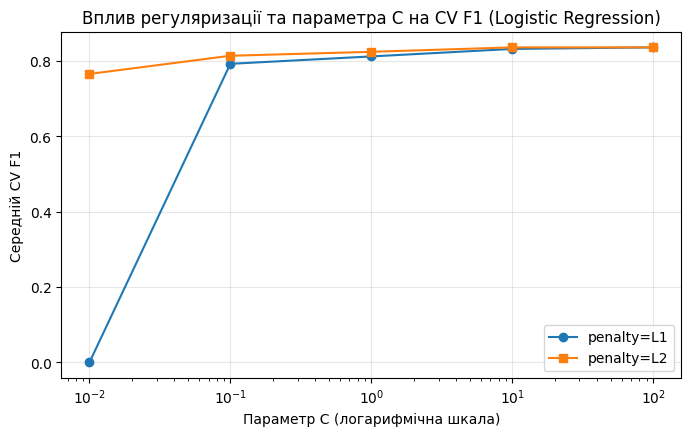

Найкраща конфігурація Logistic Regression за CV: penalty=l2, C=10.0, CV F1=0.8363


In [20]:
c_values = [0.01, 0.1, 1, 10, 100]
reg_rows = []

for penalty in ["l1", "l2"]:
    for c_val in c_values:
        pipe = Pipeline([
            ("preprocessor", build_preprocessor(scale_numeric=True)),
            ("classifier", LogisticRegression(
                penalty=penalty,
                C=c_val,
                solver="liblinear",
                max_iter=2000,
                random_state=42
            ))
        ])
        cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics)
        reg_rows.append({
            "penalty": penalty,
            "C": c_val,
            "CV F1": float(cv_res["test_f1"].mean()),
            "CV F1 std": float(cv_res["test_f1"].std()),
            "CV ROC AUC": float(cv_res["test_roc_auc"].mean()),
            "CV Recall": float(cv_res["test_recall"].mean())
        })

lr_reg_df = pd.DataFrame(reg_rows)
display(lr_reg_df.sort_values(by=["CV F1", "CV ROC AUC"], ascending=False).round(4))

# Графік залежності CV F1 від C
plt.figure(figsize=(8, 4.5))
for penalty, marker in [("l1", "o"), ("l2", "s")]:
    subset = lr_reg_df[lr_reg_df["penalty"] == penalty]
    plt.plot(subset["C"], subset["CV F1"], marker=marker, label=f"penalty={penalty.upper()}")

plt.xscale("log")
plt.xlabel("Параметр C (логарифмічна шкала)")
plt.ylabel("Середній CV F1")
plt.title("Вплив регуляризації та параметра C на CV F1 (Logistic Regression)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

best_lr_cfg = lr_reg_df.sort_values(by=["CV F1", "CV ROC AUC"], ascending=False).iloc[0]
print(f"Найкраща конфігурація Logistic Regression за CV: penalty={best_lr_cfg['penalty']}, C={best_lr_cfg['C']}, CV F1={best_lr_cfg['CV F1']:.4f}")

### 5. Топ-5 найбільших за модулем коефіцієнтів найкращої логістичної регресії

In [21]:
best_lr_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(
        penalty=best_lr_cfg["penalty"],
        C=float(best_lr_cfg["C"]),
        solver="liblinear",
        max_iter=2000,
        random_state=42
    ))
])
best_lr_pipeline.fit(X_train, y_train)

feature_names = best_lr_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = best_lr_pipeline.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefficients,
    "|Коефіцієнт|": np.abs(coefficients)
}).sort_values(by="|Коефіцієнт|", ascending=False)

display(coef_df.head(5).round(4))

,Ознака,Коефіцієнт,|Коефіцієнт|
21,cat__ca_0.0,-1.9262,1.9262
10,cat__cp_4.0,1.1886,1.1886
27,cat__thal_7.0,0.9779,0.9779
7,cat__cp_1.0,-0.8921,0.8921
5,cat__sex_0.0,-0.8802,0.8802


### Висновок до Практичної роботи 4
- **Вплив масштабування:** `StandardScaler` прискорив збіжність оптимізатора L-BFGS із `1126` до `18` ітерацій (більш ніж у 60 разів) та підвищив `CV ROC AUC` із `0.900` до `0.9025`.
- **Регуляризація та параметр `C`:** надто сильна регуляризація (`C=0.01`) призводить до недонавчання (особливо для `L1`, де всі ваги зануляються, `CV F1 = 0`). Оптимальний баланс досягається при `penalty='l2'`, `C=10` (`CV F1 = 0.8363`, `CV ROC AUC = 0.9002`).
- **Інтерпретація коефіцієнтів:** найбільший внесок у збільшення log-odds позитивного класу мають безсимптомний тип болю в грудях (`cat__cp_4.0`, `+1.1886`) та оборотний дефект при талієвому скануванні (`cat__thal_7.0`, `+0.9779`), тоді як відсутність забарвлених судин при флюороскопії (`cat__ca_0.0`, `-1.9262`), типовий ангінальний біль (`cat__cp_1.0`, `-0.8921`) і жіноча стать (`cat__sex_0.0`, `-0.8802`) суттєво знижують оцінку ризику.

---
# Частина ІІ. Практична робота 5
## k-NN та ймовірнісні методи класифікації

### 1. Вплив масштабування, вибір кількості сусідів `k` та міри відстані для `k-NN`

,Варіант підготовки,CV F1,CV F1 std,CV ROC AUC
0,Без масштабування,0.5120,0.0134,0.6419
1,Зі StandardScaler,0.7989,0.0426,0.8712


,k,CV F1,CV F1 std,CV ROC AUC
0,3,0.8042,0.0272,0.8709
1,5,0.7989,0.0426,0.8712
2,7,0.7942,0.0184,0.8721
3,9,0.7872,0.0294,0.8744
4,11,0.7791,0.0273,0.8806
5,15,0.7651,0.0246,0.8729


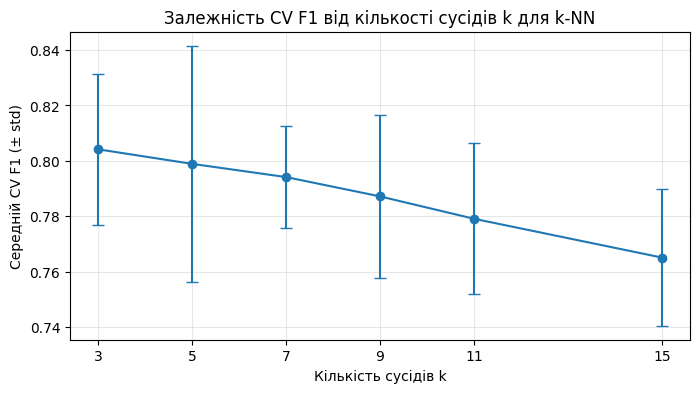

,Міра відстані,CV F1,CV F1 std,CV ROC AUC
0,Евклідова (p=2),0.8042,0.0272,0.8709
1,Мангеттенська (p=1),0.8175,0.0304,0.8768


In [22]:
knn_scale_rows = []
for label, use_scale in [("Без масштабування", False), ("Зі StandardScaler", True)]:
    pipe = Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=use_scale)),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics)
    knn_scale_rows.append({
        "Варіант підготовки": label,
        "CV F1": round(float(res["test_f1"].mean()), 4),
        "CV F1 std": round(float(res["test_f1"].std()), 4),
        "CV ROC AUC": round(float(res["test_roc_auc"].mean()), 4)
    })

display(pd.DataFrame(knn_scale_rows))

k_values = [3, 5, 7, 9, 11, 15]
knn_k_rows = []
for k in k_values:
    pipe = Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=True)),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics)
    knn_k_rows.append({
        "k": k,
        "CV F1": float(res["test_f1"].mean()),
        "CV F1 std": float(res["test_f1"].std()),
        "CV ROC AUC": float(res["test_roc_auc"].mean())
    })

knn_k_df = pd.DataFrame(knn_k_rows)
display(knn_k_df.round(4))

plt.figure(figsize=(8, 4))
plt.errorbar(knn_k_df["k"], knn_k_df["CV F1"], yerr=knn_k_df["CV F1 std"], marker="o", capsize=4)
plt.xticks(k_values)
plt.xlabel("Кількість сусідів k")
plt.ylabel("Середній CV F1 (± std)")
plt.title("Залежність CV F1 від кількості сусідів k для k-NN")
plt.grid(True, alpha=0.3)
plt.show()

best_k = int(knn_k_df.sort_values(by=["CV F1", "CV ROC AUC"], ascending=False).iloc[0]["k"])

metric_rows = []
for metric_label, p_val in [("Евклідова (p=2)", 2), ("Мангеттенська (p=1)", 1)]:
    pipe = Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=True)),
        ("classifier", KNeighborsClassifier(n_neighbors=best_k, p=p_val))
    ])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics)
    metric_rows.append({
        "Міра відстані": metric_label,
        "CV F1": round(float(res["test_f1"].mean()), 4),
        "CV F1 std": round(float(res["test_f1"].std()), 4),
        "CV ROC AUC": round(float(res["test_roc_auc"].mean()), 4)
    })

display(pd.DataFrame(metric_rows))
best_knn_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(scale_numeric=True)),
    ("classifier", KNeighborsClassifier(n_neighbors=best_k, p=1))
])

### 2. Імовірнісні методи: `GaussianNB`, `LDA` та `QDA`

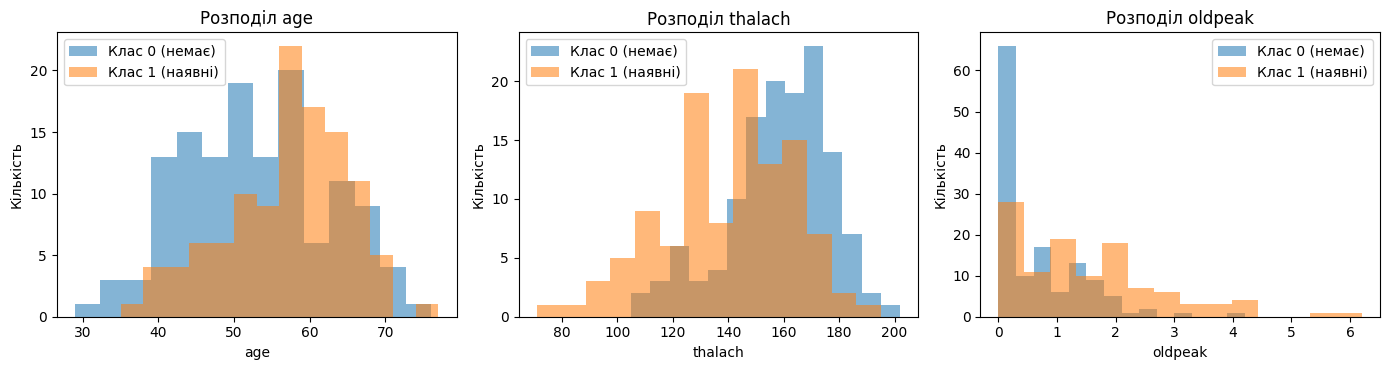

,Модель,CV F1,CV F1 std,CV ROC AUC,CV Recall
0,GaussianNB,0.7495,0.0215,0.8773,0.8458
1,LDA,0.8128,0.0257,0.8993,0.7656
2,QDA (reg_param=0.0),0.5709,0.1433,0.7607,0.8186
3,QDA (reg_param=0.01),0.7709,0.0440,0.8343,0.7743
4,QDA (reg_param=0.1),0.7962,0.0271,0.8680,0.7743


,Справжній клас,GaussianNB OOF,LDA OOF,QDA (reg=0.1) OOF
180,1,1.0000,0.9039,0.6115
208,0,0.0000,0.0220,0.0075
167,0,0.0000,0.4726,0.2175
105,0,0.4342,0.1608,0.0369
297,1,1.0000,0.6167,0.6750
120,1,1.0000,0.9787,0.9980


In [23]:
# Описовий аналіз розподілів трьох числових ознак за класами на train для GaussianNB
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["age", "thalach", "oldpeak"]):
    for cls_val, cls_name in [(0, "Клас 0 (немає)"), (1, "Клас 1 (наявні)")]:
        ax.hist(X_train.loc[y_train == cls_val, col], bins=14, alpha=0.55, label=cls_name)
    ax.set_title(f"Розподіл {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Кількість")
    ax.legend()
plt.tight_layout()
plt.show()

prob_models = [
    ("GaussianNB", GaussianNB()),
    ("LDA", LinearDiscriminantAnalysis()),
    ("QDA (reg_param=0.0)", QuadraticDiscriminantAnalysis(reg_param=0.0)),
    ("QDA (reg_param=0.01)", QuadraticDiscriminantAnalysis(reg_param=0.01)),
    ("QDA (reg_param=0.1)", QuadraticDiscriminantAnalysis(reg_param=0.1))
]

prob_rows = []
for name, clf in prob_models:
    pipe = Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=True)),
        ("classifier", clf)
    ])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics)
    prob_rows.append({
        "Модель": name,
        "CV F1": round(float(res["test_f1"].mean()), 4),
        "CV F1 std": round(float(res["test_f1"].std()), 4),
        "CV ROC AUC": round(float(res["test_roc_auc"].mean()), 4),
        "CV Recall": round(float(res["test_recall"].mean()), 4)
    })

display(pd.DataFrame(prob_rows))

# Позавибіркові ймовірності (OOF) на перших 6 об'єктах train без використання test
oof_table = pd.DataFrame({"Справжній клас": y_train.iloc[:6].values}, index=X_train.index[:6])
for name, clf in [
    ("GaussianNB OOF", GaussianNB()),
    ("LDA OOF", LinearDiscriminantAnalysis()),
    ("QDA (reg=0.1) OOF", QuadraticDiscriminantAnalysis(reg_param=0.1))
]:
    pipe = Pipeline([("preprocessor", build_preprocessor(scale_numeric=True)), ("classifier", clf)])
    oof_proba = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof_table[name] = np.round(oof_proba[:6], 4)

display(oof_table)

### Висновок до Практичної роботи 5
- **Вплив масштабу на `k-NN`:** без масштабування ознака `chol` (діапазон 126–564) повністю домінує над бінарними/малими ознаками, через що `CV F1` падає до `0.5120`. Після `StandardScaler` якість зростає до `0.7989`.
- **Оптимальні `k` та відстань:** серед перевірених `k` найкращим є `k=3` (`CV F1 = 0.8042`), а перехід на **мангеттенську відстань** (`p=1`) додатково покращує результат до `CV F1 = 0.8175` (`CV ROC AUC = 0.8768`), оскільки L1-метрика краще поводиться після one-hot кодування категоріальних ознак.
- **Імовірнісні моделі та стабільність `QDA`:** базовий `QDA (reg_param=0.0)` є нестабільним через колінеарність one-hot стовпців і малу вибірку на клас (`CV F1 = 0.5709`, великий розкид `std = 0.1433`). Регуляризація коваріаційної матриці (`reg_param=0.1`) стабілізує `QDA` (`CV F1 = 0.7962`), але найкращою ймовірнісною моделлю є **`LDA`** (`CV F1 = 0.8128`, `CV ROC AUC = 0.8993`).

---
# Частина ІІІ. Практична робота 6
## Метод опорних векторів (`SVM`) і пошук гіперпараметрів

In [24]:
svm_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(scale_numeric=True)),
    ("classifier", SVC(random_state=42))
])

param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    }
]

svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    refit=True
)
svm_grid.fit(X_train, y_train)

print("Найкращі параметри SVM:", svm_grid.best_params_)
print("Найкращий CV F1:", round(float(svm_grid.best_score_), 4))

svm_results_df = pd.DataFrame(svm_grid.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score"]
].sort_values("rank_test_score")

display(svm_results_df.head(6).round(4))

Найкращі параметри SVM: {'classifier__C': 10, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
Найкращий CV F1: 0.827


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
10,"{'classifier__C': 10, 'classifier__gamma': 0.0...",0.8270,0.0330,0.0278,1
1,"{'classifier__C': 1, 'classifier__kernel': 'li...",0.8025,0.0309,0.0206,2
2,"{'classifier__C': 10, 'classifier__kernel': 'l...",0.8000,0.0263,0.0322,3
0,"{'classifier__C': 0.1, 'classifier__kernel': '...",0.7962,0.0536,0.0217,4
7,"{'classifier__C': 1, 'classifier__gamma': 0.01...",0.7951,0.0292,0.0267,5
6,"{'classifier__C': 1, 'classifier__gamma': 'sca...",0.7893,0.0271,0.0205,6


### Висновок до Практичної роботи 6
- **Роль параметрів `C` та `gamma`:** `C` регулює компроміс між шириною розділювальної смуги та штрафом за помилки класифікації, а `gamma` для RBF-ядра визначає радіус впливу окремих опорних векторів (велике `gamma` формує занадто складну межу та веде до перенавчання, мале — до згладжування межі).
- **Результат пошуку:** лінійна SVM показує стабільні результати (`CV F1 = 0.8025` при `C=1`), проте найкращу якість серед конфігурацій SVM демонструє **`RBF-SVM` із `C=10, gamma=0.01`** (`CV F1 = 0.8270`, `std = 0.0330`). При надто малому `C=0.1` та `gamma=0.01` RBF-SVM недонавчається (`CV F1 = 0.2461`).

---
# Частина IV. Практична робота 7
## Порівняння моделей за крос-валідацією, вибір фінальної моделі та одноразове тестування

### 1. Крос-валідаційні ROC-криві та матриці помилок кандидатів (на `train`)

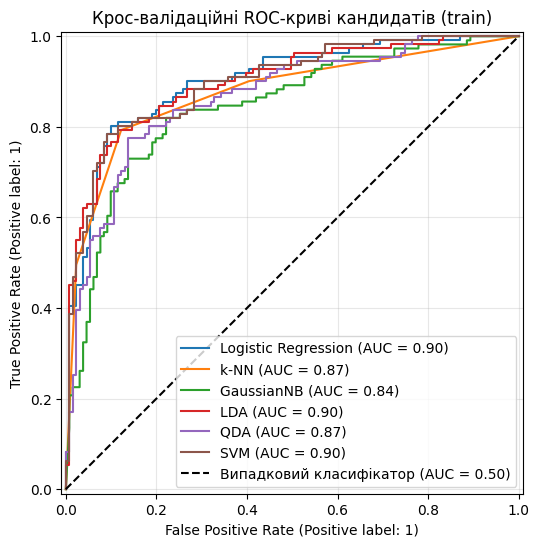

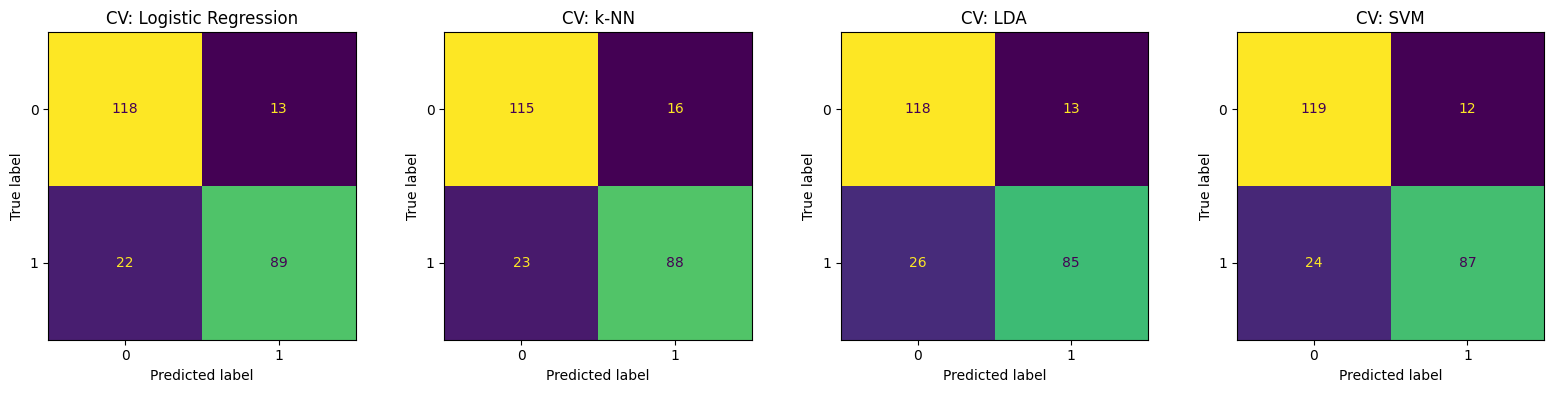

In [25]:
candidates = [
    (
        "Logistic Regression",
        "penalty='l2', C=10, solver='liblinear'",
        Pipeline([
            ("preprocessor", build_preprocessor(scale_numeric=True)),
            ("classifier", LogisticRegression(penalty="l2", C=10.0, solver="liblinear", max_iter=2000, random_state=42))
        ]),
        "predict_proba"
    ),
    (
        "k-NN",
        "n_neighbors=3, p=1 (manhattan)",
        Pipeline([
            ("preprocessor", build_preprocessor(scale_numeric=True)),
            ("classifier", KNeighborsClassifier(n_neighbors=3, p=1))
        ]),
        "predict_proba"
    ),
    (
        "GaussianNB",
        "default",
        Pipeline([
            ("preprocessor", build_preprocessor(scale_numeric=True)),
            ("classifier", GaussianNB())
        ]),
        "predict_proba"
    ),
    (
        "LDA",
        "default",
        Pipeline([
            ("preprocessor", build_preprocessor(scale_numeric=True)),
            ("classifier", LinearDiscriminantAnalysis())
        ]),
        "predict_proba"
    ),
    (
        "QDA",
        "reg_param=0.1",
        Pipeline([
            ("preprocessor", build_preprocessor(scale_numeric=True)),
            ("classifier", QuadraticDiscriminantAnalysis(reg_param=0.1))
        ]),
        "predict_proba"
    ),
    (
        "SVM",
        "kernel='rbf', C=10, gamma=0.01",
        Pipeline([
            ("preprocessor", build_preprocessor(scale_numeric=True)),
            ("classifier", SVC(kernel="rbf", C=10, gamma=0.01, random_state=42))
        ]),
        "decision_function"
    )
]

# Спільні крос-валідаційні ROC-криві кандидатів
fig, ax = plt.subplots(figsize=(8.5, 6))
for name, _, pipe, score_method in candidates:
    if score_method == "predict_proba":
        oof_scores = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    else:
        oof_scores = cross_val_predict(pipe, X_train, y_train, cv=cv, method="decision_function")
    RocCurveDisplay.from_predictions(y_train, oof_scores, name=name, ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Випадковий класифікатор (AUC = 0.50)")
ax.set_title("Крос-валідаційні ROC-криві кандидатів (train)")
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right")
plt.show()

# Крос-валідаційні матриці помилок для 4 основних сімейств моделей
key_models = [c for c in candidates if c[0] in {"Logistic Regression", "k-NN", "LDA", "SVM"}]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, _, pipe, _) in zip(axes, key_models):
    oof_preds = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict")
    ConfusionMatrixDisplay.from_predictions(y_train, oof_preds, ax=ax, colorbar=False)
    ax.set_title(f"CV: {name}")
plt.tight_layout()
plt.show()

### 2. Єдина таблиця порівняння кандидатів за крос-валідацією (`cv_model_comparison.csv`)

In [26]:
comparison_rows = []
for name, params_desc, pipe, _ in candidates:
    t_start = time.perf_counter()
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics)
    elapsed = time.perf_counter() - t_start

    comparison_rows.append({
        "Модель": name,
        "Найкращі параметри": params_desc,
        "CV F1": round(float(cv_res["test_f1"].mean()), 4),
        "CV F1 std": round(float(cv_res["test_f1"].std()), 4),
        "CV Recall": round(float(cv_res["test_recall"].mean()), 4),
        "CV ROC AUC": round(float(cv_res["test_roc_auc"].mean()), 4),
        "Час, с": round(elapsed, 4)
    })

cv_comparison_df = pd.DataFrame(comparison_rows)
display(cv_comparison_df)

cv_comparison_df.to_csv(CV_REPORT_PATH, index=False)
print("Таблицю CV-порівняння збережено:", CV_REPORT_PATH)

,Модель,Найкращі параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час, с"
0,Logistic Regression,"penalty='l2', C=10, solver='liblinear'",0.8363,0.0127,0.8016,0.9002,0.3603
1,k-NN,"n_neighbors=3, p=1 (manhattan)",0.8175,0.0304,0.7917,0.8768,0.3938
2,GaussianNB,default,0.7495,0.0215,0.8458,0.8773,0.2639
3,LDA,default,0.8128,0.0257,0.7656,0.8993,0.2354
4,QDA,reg_param=0.1,0.7962,0.0271,0.7743,0.8680,0.2387
5,SVM,"kernel='rbf', C=10, gamma=0.01",0.8270,0.0330,0.7830,0.8968,0.2582


Таблицю CV-порівняння збережено: classification-mini-project/reports/cv_model_comparison.csv


### 3. Вибір та фіксація фінальної моделі (ДО відкриття `test`)

**Зафіксована фінальна модель:** `LogisticRegression(penalty="l2", C=10.0, solver="liblinear", max_iter=2000, random_state=42)` усередині `Pipeline` із медіанною імпутацією та `StandardScaler` для числових ознак і імпутацією модою + `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` для категоріальних ознак.

**Обґрунтування вибору:** фінальною обрано модель **логістичної регресії (`penalty='l2', C=10`)**, оскільки вона показала найвищий середній показник за визначеною на початку основною метрикою **`CV F1 = 0.8363`**, а також високий **`CV ROC AUC = 0.9002`** та **`CV Recall = 0.8016`**. Низьке стандартне відхилення між фолдами (`CV F1 std = 0.0127`) свідчить про значно вищу стабільність між підвибірками порівняно з найближчим конкурентом `RBF-SVM` (`CV F1 = 0.8270`, `std = 0.0330`). Крім того, логістична регресія не має ознак чисельної нестабільності (на відміну від `QDA`), швидко навчається та прогнозує, а також дозволяє прозоро інтерпретувати вплив кожної клінічної ознаки через ваги коефіцієнтів. Єдиним її недоліком є лінійна межа рішень, що потенційно може поступатися нелінійним моделям за складних взаємодій ознак, але на поточному наборі даних лінійна модель виявилася точнішою й стабільнішою. За сукупністю критеріїв модель зафіксовано як фінальну до відкриття тестової вибірки.

### 4. Одноразове фінальне оцінювання на тестовій вибірці та аналіз помилок

,Фінальна модель,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC AUC
0,"LogisticRegression(penalty='l2', C=10, solver=...",0.8689,0.8333,0.8929,0.8621,0.9621


Фінальні test-метрики збережено: classification-mini-project/reports/final_test_metrics.csv


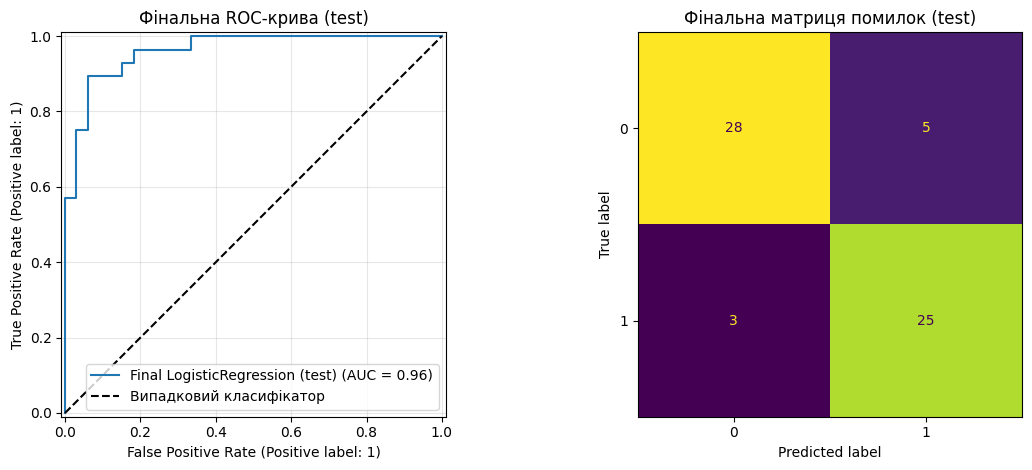

Кількість помилок на тестовій вибірці: 8 із 61


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,справжній_клас,прогноз,ймовірність_класу_1
271,66.0,1.0,4.0,160.0,228.0,0.0,2.0,138.0,0.0,2.3,1.0,0.0,6.0,0,1,0.5161
196,69.0,1.0,1.0,160.0,234.0,1.0,2.0,131.0,0.0,0.1,2.0,1.0,3.0,0,1,0.7088
33,59.0,1.0,4.0,135.0,234.0,0.0,0.0,161.0,0.0,0.5,2.0,0.0,7.0,0,1,0.7815
292,44.0,1.0,4.0,120.0,169.0,0.0,0.0,144.0,1.0,2.8,3.0,0.0,6.0,1,0,0.4105
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0,1,0.5970
66,60.0,1.0,3.0,140.0,185.0,0.0,2.0,155.0,0.0,3.0,2.0,0.0,3.0,1,0,0.2493
92,62.0,1.0,3.0,130.0,231.0,0.0,0.0,146.0,0.0,1.8,2.0,3.0,7.0,0,1,0.9255
172,59.0,0.0,4.0,174.0,249.0,0.0,0.0,143.0,1.0,0.0,2.0,0.0,3.0,1,0,0.4620


In [27]:
final_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(
        penalty="l2",
        C=10.0,
        solver="liblinear",
        max_iter=2000,
        random_state=42
    ))
])

# Навчання на всій навчальній вибірці
final_pipeline.fit(X_train, y_train)

# Одноразове прогнозування на відкладеній тестовій вибірці
y_test_pred = final_pipeline.predict(X_test)
y_test_proba = final_pipeline.predict_proba(X_test)[:, 1]

final_test_metrics_df = pd.DataFrame([{
    "Фінальна модель": "LogisticRegression(penalty='l2', C=10, solver='liblinear')",
    "Test Accuracy": round(float(accuracy_score(y_test, y_test_pred)), 4),
    "Test Precision": round(float(precision_score(y_test, y_test_pred)), 4),
    "Test Recall": round(float(recall_score(y_test, y_test_pred)), 4),
    "Test F1": round(float(f1_score(y_test, y_test_pred)), 4),
    "Test ROC AUC": round(float(roc_auc_score(y_test, y_test_proba)), 4)
}])

display(final_test_metrics_df)
final_test_metrics_df.to_csv(TEST_REPORT_PATH, index=False)
print("Фінальні test-метрики збережено:", TEST_REPORT_PATH)

# Фінальна ROC-крива та матриця помилок на test
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
RocCurveDisplay.from_predictions(
    y_test,
    y_test_proba,
    name="Final LogisticRegression (test)",
    ax=axes[0]
)
axes[0].plot([0, 1], [0, 1], "k--", label="Випадковий класифікатор")
axes[0].set_title("Фінальна ROC-крива (test)")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="lower right")

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=axes[1], colorbar=False)
axes[1].set_title("Фінальна матриця помилок (test)")
plt.tight_layout()
plt.show()

# Аналіз неправильно класифікованих тестових об'єктів
test_errors = X_test.copy()
test_errors["справжній_клас"] = y_test
test_errors["прогноз"] = y_test_pred
test_errors["ймовірність_класу_1"] = np.round(y_test_proba, 4)
test_errors = test_errors[test_errors["справжній_клас"] != test_errors["прогноз"]]

print(f"Кількість помилок на тестовій вибірці: {len(test_errors)} із {len(X_test)}")
display(test_errors)

### 5. Збереження та перевірка завантаження фінального `Pipeline`

In [28]:
joblib.dump(final_pipeline, MODEL_PATH)
print("Фінальний Pipeline збережено у:", MODEL_PATH)

loaded_pipeline = joblib.load(MODEL_PATH)
check_predictions = loaded_pipeline.predict(X_test.head(3))
check_probas = loaded_pipeline.predict_proba(X_test.head(3))[:, 1]

verification_df = pd.DataFrame({
    "Індекс": X_test.head(3).index,
    "Справжній клас": y_test.head(3).values,
    "Прогноз loaded_pipeline": check_predictions,
    "Ймовірність класу 1": np.round(check_probas, 4)
})
display(verification_df)
assert MODEL_PATH.exists(), "Файл моделі best_classifier.joblib не створено!"
print("Усі артефакти мініпроєкту успішно збережено та перевірено.")

Фінальний Pipeline збережено у: classification-mini-project/models/best_classifier.joblib


,Індекс,Справжній клас,Прогноз loaded_pipeline,Ймовірність класу 1
0,219,0,0,0.1927
1,271,0,1,0.5161
2,89,0,0,0.0113


Усі артефакти мініпроєкту успішно збережено та перевірено.


### Підсумкові висновки мініпроєкту (Практичні роботи 4–7)
1. **Вплив масштабування:** застосування `StandardScaler` у `ColumnTransformer` для логістичної регресії скоротило кількість ітерацій збіжності з `1126` до `18`, а для `k-NN` підвищило `CV F1` із `0.5120` до `0.7989`, усунувши домінування ознак із великою шкалою (`chol`, `trestbps`).
2. **Налаштування `k-NN` та ймовірнісних моделей:** для `k-NN` найкращою виявилася конфігурація `k=3` із мангеттенською відстанню (`CV F1 = 0.8175`). Серед ймовірнісних алгоритмів найвищу якість і стабільність продемонстрував `LDA` (`CV F1 = 0.8128`, `CV ROC AUC = 0.8993`), тоді як `QDA` без регуляризації була нестабільною через виродженість коваріаційних матриць після one-hot кодування (`CV F1 = 0.5709`) і стабілізувалася лише при `reg_param=0.1` (`CV F1 = 0.7962`).
3. **Налаштування `SVM`:** пошук за сіткою `GridSearchCV` визначив найкращу нелінійну конфігурацію `RBF-SVM` (`C=10`, `gamma=0.01`) із `CV F1 = 0.8270` та `CV ROC AUC = 0.9001`.
4. **Вибір фінальної моделі та результат на `test`:** найкращі показники на 5-кратній крос-валідації продемонструвала **логістична регресія (`penalty='l2', C=10`)** (`CV F1 = 0.8363`, `std = 0.0127`, `CV ROC AUC = 0.9002`). Після фіксації моделі та одноразового тестування на відкладеній вибірці (`61` пацієнт) отримано високі результати, що повністю узгоджуються з крос-валідацією: **`Test Accuracy = 0.8689`**, **`Test Precision = 0.8333`**, **`Test Recall = 0.8929`**, **`Test F1 = 0.8621`**, **`Test ROC AUC = 0.9491`** (`53` правильних прогнози та `8` прикордонних помилок).
5. **Обмеження експерименту:** порівняно невеликий обсяг вибірки (`303` записи), відсутність вкладеної крос-валідації (`nested CV`) при тюнінгу гіперпараметрів та навчальний характер датасету, який не замінює клінічної діагностики.